# IA26_P01_G02 — Pesquisa informada: UCS, Greedy e A*

**Protótipo** feito por Alexandre Silva (29382) · Grupo 02 · Inteligência Artificial 2026/27

> Na divisão final do grupo, a pesquisa informada é do Fábio. Este protótipo serve para gerar a solução inicial do Greedy usada na pesquisa local (`../pesquisa_local/`) e como referência (o ótimo do A\*).

**O que este notebook faz:**
1. Define a pesquisa sobre o `model.py` do grupo: estado, ações (sucessores), objetivo e custo.
2. Implementa as duas heurísticas oficiais do grupo:
   - **H1 — pedido mais caro**;
   - **H2 — árvore geradora mínima (MST)**.
3. Compara o **UCS** (sem heurística, dá o ótimo), o **Greedy** e o **A\*** com cada heurística: distância, nós expandidos e tempo.
4. Apresenta as rotas dos 2 veículos do *tiny* (entregável do guia) e repete a análise no *small*.

Como referência, também aparecem a heurística "paragem mais distante" do Fábio (adaptada ao dia) e a combinação `max(H1, H2)`.

**Ficheiros desta pasta:**
| Ficheiro | Conteúdo |
|---|---|
| `heuristicas.py` | H1, H2 e as heurísticas de referência |
| `pesquisa.py` | Subproblema, sucessores, UCS/Greedy/A*, atribuição das encomendas aos veículos, validação |
| `02_pesquisa_informada.ipynb` | Este notebook |

O código usa diretamente o `model.py` da raiz do repositório (`Problem`, `State`, `verificar_viabilidade`). Para correr, basta abrir este notebook dentro da pasta `pesquisa_informada/` e executar todas as células.

In [1]:
import sys, time, itertools
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, ".")    # heuristicas.py e pesquisa.py
sys.path.insert(0, "..")   # model.py (raiz do repositório)

from model import Problem, State
from heuristicas import (h_zero, h_pedido_mais_caro, h_mst, h_mais_distante,
                         h_max_h1_h2, HEURISTICAS, paragens_pendentes)
from pesquisa import (Subproblema, pesquisar, planear, melhor_atribuicao, validar,
                      verificar_admissibilidade, dias_do_problema)

PASTA_TINY = "../docs/data_tiny/"
PASTA_SMALL = "../docs/data_small_30_31oct2026/"

tiny = Problem(PASTA_TINY)
small = Problem(PASTA_SMALL)

for nome, pb in [("tiny", tiny), ("small", small)]:
    print(f"{nome:5s}: armazém = paragem {pb.armazem} | {len(pb.paragens)} paragens | "
          f"{len(pb.pedidos)} itens | {len({r.order_id for r in pb.pedidos.values()})} encomendas | "
          f"veículos {[ (v.vehicle_id, v.capacity_kg) for v in pb.veiculos.values()]}")

tiny : armazém = paragem 4 | 9 paragens | 40 itens | 12 encomendas | veículos [(1, 150.0), (2, 200.0)]
small: armazém = paragem 7 | 14 paragens | 80 itens | 25 encomendas | veículos [(1, 250.0), (2, 300.0)]


## 1. Modelação da pesquisa

### 1.1 Decisões de modelação

| Decisão | Porquê |
|---|---|
| **Um subproblema por veículo e por dia.** Cada dia começa às 06:00 no armazém e acaba no armazém. | O horizonte tem 2 dias e o veículo volta sempre à base. Dividir assim torna cada pesquisa pequena o suficiente para o A\* e o UCS. |
| **O que passa a noite no armazém transita para o dia seguinte** com a hora de chegada (o `chegada_armazem_previa` do `verificar_viabilidade`). | Respeita o limite de 24 h no armazém, que é verificado no carregamento. |
| **Os itens de uma encomenda são entregues juntos** e cada encomenda do próprio dia é recolhida e entregue pelo mesmo veículo. | Decisão da EDA. Evita ter de sincronizar dois veículos no armazém no mesmo dia. |
| **Encomendas que passam a noite no armazém podem ser entregues pelo outro veículo.** | O armazém é partilhado. Como o dia anterior já está resolvido, não há sincronização a fazer. |
| **Custo g(n) = km reais percorridos** (matriz original). As heurísticas usam `distancia_minima` (Floyd-Warshall). | O objetivo do guia é minimizar a distância. O tempo entra como restrição (janelas, 24 h). |

### 1.2 Estado, ações, objetivo

- **Estado** (`model.State`): paragem atual, hora, carga, e onde está cada item: por recolher, recolhido a bordo, no armazém (com hora de chegada), carregado para entrega ou entregue.
- **Ações** (cada uma é uma visita a uma paragem):
  - **recolher num produtor**: leva os itens cuja janela de disponibilidade permite começar o serviço. Há uma variante por cada hora de abertura de janela, ou seja, o veículo pode esperar. A capacidade é respeitada.
  - **ir ao armazém**: descarrega o que foi recolhido (15 min) e carrega as encomendas de hoje que já estão completas, ainda a tempo e dentro das 24 h (15 min). Também há a variante de só descarregar.
  - **entregar num cliente**: entrega as encomendas carregadas cujo destino é esse cliente. Também tem uma variante por hora de abertura de janela.
- **Objetivo:** tudo o que é de hoje recolhido e descarregado, tudo o que é de hoje entregue, e o veículo vazio no armazém.
- **Poda:** um estado é descartado quando algum item já não pode ser servido a tempo (beco sem saída). Também é descartado quando é **dominado**, ou seja, quando já existe outro estado com os mesmos itens no mesmo sítio, com menos ou igual distância e a hora igual ou mais cedo.

As ações produzem listas no formato do `verificar_viabilidade` do `model.py` (`pickup`, `warehouse`, `load`, `delivery`). **Todas as rotas encontradas são confirmadas por esse verificador**, incluindo os km.

### 1.3 Algoritmos

| Algoritmo | Prioridade na fronteira | Garante o ótimo? |
|---|---|---|
| UCS | g(n) | Sim |
| Greedy Best-First | h(n) | Não |
| A\* | g(n) + h(n) | Sim, com uma heurística admissível |

Os três usam o mesmo código (`pesquisa.pesquisar`). Só muda a prioridade. Contamos os **nós expandidos** (estados retirados da fronteira e desenvolvidos) e os **nós gerados**.

## 2. Heurísticas

Todas as heurísticas estimam os km que faltam até ao objetivo e usam as distâncias mínimas `d(x, y)` do Floyd-Warshall, que nunca são maiores do que as reais.

Cada item ainda pendente obriga o veículo a visitar estas paragens, por esta ordem:

| Situação do item | Percurso obrigatório que falta |
|---|---|
| Por recolher, entregue hoje | atual → produtor → armazém → cliente → armazém |
| Por recolher, entregue amanhã | atual → produtor → armazém |
| Recolhido a bordo | atual → armazém (→ cliente → armazém, se for de hoje) |
| No armazém, entregue hoje | atual → armazém → cliente → armazém |
| Carregado para entrega | atual → cliente → armazém |

### H1 — pedido mais caro (oficial)
$$h_1(n) = \max_{\text{item } i} \; \text{custo do percurso obrigatório de } i$$
**Admissível:** a rota real tem de passar pelas paragens de cada item, por essa ordem. Por isso nunca custa menos do que o percurso do item mais caro. **Tem de ser o máximo e não a soma.** A soma sobrestima, porque a mesma viagem serve vários itens ao mesmo tempo.

### H2 — árvore geradora mínima, MST (oficial)
Sendo $P$ o conjunto de paragens pendentes:
$$h_2(n) = \min_{p \in P} d(\text{atual}, p) + \text{MST}(P) + \min_{p \in P} d(p, \text{armazém})$$
**Admissível:** a rota que falta tem três partes. Sai da posição atual para uma primeira paragem pendente, percorre todas as pendentes (qualquer caminho que as ligue custa pelo menos a MST) e volta ao armazém a partir da última. Cada parte custa, no mínimo, o termo correspondente. A MST é calculada com o algoritmo de Prim sobre um dicionário, porque é chamada milhares de vezes. As distâncias 0 entre paragens diferentes contam como ligações válidas (no small, o produtor 4 está no armazém e as entregas 8 e 13 estão no mesmo sítio).

### Referências
- **UCS:** h = 0.
- **Ref. — paragem mais distante** (Fábio): $\max_{p \in P} d(\text{atual}, p) + d(p, \text{armazém})$. É a mesma ideia do `model.h_mais_distante`, mas sabe que os itens entregues amanhã só têm de chegar hoje ao armazém.
- **max(H1, H2):** o máximo de duas heurísticas admissíveis também é admissível.

**O que esperar:** H1 olha para uma encomenda e conhece a regra produtor → armazém → cliente. H2 liga todas as paragens, mas ignora essa regra. Por isso, H1 deve ser mais forte quando ainda faltam recolhas, e H2 quando faltam muitas paragens espalhadas.

## 3. *Tiny*

### 3.1 Atribuição das encomendas aos veículos

Antes da pesquisa, cada encomenda tem de ter um veículo. Usamos uma **inserção mais barata**:
1. As encomendas entram uma a uma, por uma certa ordem.
2. Cada uma fica no veículo (ou par de veículos recolha/entrega, se passar a noite no armazém) que mantém o plano viável com o menor aumento de km.
3. O plano é avaliado com o Greedy, que é rápido.

Testamos várias ordens de inserção (critérios de urgência e ordens aleatórias com semente fixa) e ficamos com a melhor: primeiro a que deixa menos encomendas de fora, depois a de menos km. Esta atribuição fica fixa para todos os algoritmos, para a comparação ser justa.

In [2]:
t0 = time.perf_counter()
atr_tiny, fora_tiny, tabela_ordens = melhor_atribuicao(tiny, h_pedido_mais_caro, n_aleatorias=4)
print(f"Tempo da atribuição: {time.perf_counter() - t0:.1f} s")

pd.DataFrame(tabela_ordens, columns=["ordem de inserção", "nº encomendas de fora", "de fora",
                                     "km (Greedy H1)", "tempo (s)"])

Tempo da atribuição: 3.8 s


,ordem de inserção,nº encomendas de fora,de fora,km (Greedy H1),tempo (s)
0,fim da janela de recolha,0,[],629.19,0.3
1,fim da janela de entrega,0,[],771.05,0.5
2,mais produtores primeiro,0,[],609.59,0.5
3,mais pesada primeiro,0,[],609.59,0.6
4,aleatória 1,1,[3],690.60,0.5
5,aleatória 2,1,[8],690.77,0.4
6,aleatória 3,0,[],757.13,0.3
7,aleatória 4,0,[],654.15,0.7


In [3]:
def tabela_atribuicao(pb, atr):
    linhas = []
    for oid, (vr, ve) in sorted(atr.items()):
        itens = [r for r in pb.pedidos.values() if r.order_id == oid]
        linhas.append({"encomenda": oid, "peso (kg)": round(sum(r.weight_kg for r in itens), 1),
                       "dia recolha": itens[0].dia_recolha.day, "dia entrega": itens[0].dia_entrega.day,
                       "veículo recolha": vr, "veículo entrega": ve})
    return pd.DataFrame(linhas).set_index("encomenda")

print("Encomendas de fora:", fora_tiny or "nenhuma")
tabela_atribuicao(tiny, atr_tiny).T

Encomendas de fora: nenhuma


encomenda,1,2,3,4,5,6,7,8,9,10,11,12
peso (kg),22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
dia recolha,31.0,30.0,31.0,30.0,31.0,31.0,31.0,30.0,30.0,30.0,30.0,30.0
dia entrega,31.0,31.0,31.0,30.0,31.0,31.0,31.0,31.0,31.0,30.0,30.0,30.0
veículo recolha,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
veículo entrega,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0


### 3.2 As heurísticas no estado inicial de cada subproblema

h\* é o custo ótimo real que falta, calculado com o UCS. Uma heurística admissível tem sempre h ≤ h\*. Quanto mais perto de h\*, mais informada é.

In [4]:
def subproblemas_do_plano(pb, atr):
    # o plano A* com H1 dá as horas de chegada ao armazém que passam para o dia seguinte
    plano = planear(pb, atr, "astar", h_pedido_mais_caro)
    return [r["subproblema"] for r in plano["rotas"]]

subs_tiny = subproblemas_do_plano(tiny, atr_tiny)
linhas = []
for sub in subs_tiny:
    s0 = sub.estado_inicial()
    h_estrela = pesquisar(sub, "ucs")["distancia_km"]
    linha = {"veículo": sub.vehicle_id, "dia": sub.dia.day, "h* (ótimo, km)": h_estrela}
    for nome, h in HEURISTICAS.items():
        linha[nome] = round(h(s0, sub), 2)
    linhas.append(linha)
pd.DataFrame(linhas)

,veículo,dia,"h* (ótimo, km)",H1 (pedido mais caro),H2 (MST),Ref. (mais distante),"max(H1, H2)"
0,1,30,273.07,147.56,146.05,75.32,147.56
1,1,31,235.11,147.56,124.66,75.32,147.56
2,2,31,93.79,72.24,57.51,72.24,72.24


### 3.3 Teste de admissibilidade

Vamos além do estado inicial. Para os estados alcançáveis de cada subproblema (até 600 por subproblema; os becos sem saída não contam, porque aí h\* é infinito), calculamos h\*(n) com o UCS a partir desse estado e contamos as vezes em que alguma heurística dá h(n) > h\*(n). A coluna `h/h* médio` mede a qualidade: 1 seria perfeito.

In [5]:
def tabela_admissibilidade(subs, max_estados=150):
    linhas = []
    for sub in subs:
        stats = verificar_admissibilidade(sub, HEURISTICAS, max_estados=max_estados)
        for nome, st in stats.items():
            linhas.append({"veículo": sub.vehicle_id, "dia": sub.dia.day, "heurística": nome,
                           "estados testados": st["estados"], "violações (h > h*)": st["violacoes"],
                           "h/h* médio": st["razao_media_h_hestrela"]})
    df = pd.DataFrame(linhas)
    resumo = df.groupby("heurística", sort=False).agg(
        estados=("estados testados", "sum"), violacoes=("violações (h > h*)", "sum"),
        h_sobre_hestrela=("h/h* médio", "mean")).round(3)
    return df, resumo

adm_tiny, resumo_adm_tiny = tabela_admissibilidade(subs_tiny, max_estados=600)
resumo_adm_tiny

,estados,violacoes,h_sobre_hestrela
heurística,,,
H1 (pedido mais caro),84,0,0.730
H2 (MST),84,0,0.614
Ref. (mais distante),84,0,0.702
"max(H1, H2)",84,0,0.734


### 3.4 Comparação dos algoritmos

Cada configuração resolve o plano completo: 2 veículos × 2 dias. Os números são a soma dos 4 subproblemas.

In [6]:
CONFIGURACOES = [("UCS", "ucs", "—", h_zero)] + [
    (alg, est, nome, h)
    for alg, est in [("Greedy", "greedy"), ("A*", "astar")]
    for nome, h in HEURISTICAS.items()
]

def comparar(pb, atr, repeticoes=3):
    linhas, planos = [], {}
    for alg, est, nome, h in CONFIGURACOES:
        tempos = []
        for _ in range(repeticoes):  # o tempo é a mediana de várias execuções
            plano = planear(pb, atr, est, h, max_expansoes=500_000, limite_s=300)
            tempos.append(plano["tempo_s"])
        planos[(alg, nome)] = plano
        linhas.append({"algoritmo": alg, "heurística": nome, "km": plano["distancia_km"],
                       "nós expandidos": plano["nos_expandidos"], "nós gerados": plano["nos_gerados"],
                       "tempo (ms)": round(1000 * sorted(tempos)[len(tempos) // 2], 1),
                       "rotas válidas": plano["viavel"], "terminou": plano["terminou"]})
    df = pd.DataFrame(linhas)
    otimo = df.loc[df["algoritmo"] == "UCS", "km"].iloc[0]
    df["ótimo?"] = (df["km"] - otimo).abs() < 0.01
    df["km acima do ótimo"] = (df["km"] - otimo).round(2)
    return df, planos

res_tiny, planos_tiny = comparar(tiny, atr_tiny)
res_tiny

,algoritmo,heurística,km,nós expandidos,nós gerados,tempo (ms),rotas válidas,terminou,ótimo?,km acima do ótimo
0,UCS,—,601.97,610,753,58.0,True,True,True,0.00
1,Greedy,H1 (pedido mais caro),609.59,311,530,35.0,True,True,False,7.62
2,Greedy,H2 (MST),609.59,179,323,19.0,True,True,False,7.62
3,Greedy,Ref. (mais distante),609.59,538,724,48.0,True,True,False,7.62
4,Greedy,"max(H1, H2)",609.59,281,524,39.0,True,True,False,7.62
5,A*,H1 (pedido mais caro),601.97,429,695,45.0,True,True,True,0.00
6,A*,H2 (MST),601.97,536,726,55.0,True,True,True,0.00
7,A*,Ref. (mais distante),601.97,573,732,50.0,True,True,True,0.00
8,A*,"max(H1, H2)",601.97,423,690,61.0,True,True,True,0.00


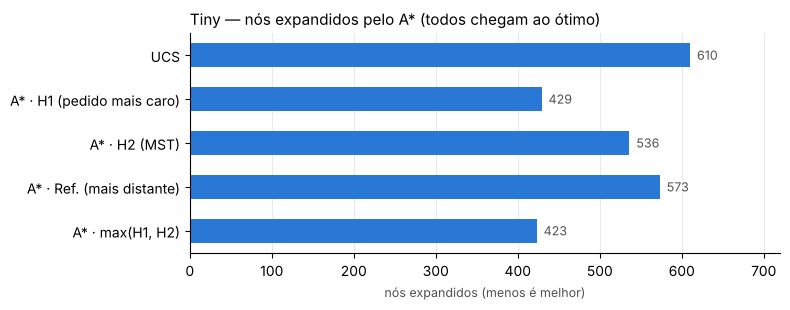

In [7]:
AZUL = "#2a78d6"   # uma única série: uma só cor

def grafico_nos(df, titulo, ax):
    sel = df[df["algoritmo"].isin(["UCS", "A*"])].copy()
    sel["rótulo"] = sel.apply(lambda r: "UCS" if r["algoritmo"] == "UCS" else f"A* · {r['heurística']}", axis=1)
    sel = sel.iloc[::-1]
    ax.barh(sel["rótulo"], sel["nós expandidos"], color=AZUL, height=0.55)
    for y, v in enumerate(sel["nós expandidos"]):
        ax.text(v, y, f"  {v}", va="center", fontsize=9, color="#52514e")
    ax.set_title(titulo, fontsize=11, loc="left")
    ax.set_xlabel("nós expandidos (menos é melhor)", fontsize=9, color="#52514e")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#e5e4df", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.set_xlim(0, sel["nós expandidos"].max() * 1.18)

fig, ax = plt.subplots(figsize=(8, 3.2))
grafico_nos(res_tiny, "Tiny — nós expandidos pelo A* (todos chegam ao ótimo)", ax)
plt.tight_layout()
plt.show()

### 3.5 Rotas dos 2 veículos do *tiny* (A\* com H1)

Este é o entregável do guia. Cada linha é uma visita, já com as esperas pelas janelas. O `verificar_viabilidade` do `model.py` confirma cada rota.

In [8]:
def mostrar_rotas(pb, plano):
    for r in plano["rotas"]:
        v = r["validacao"]
        print(f"Veículo {r['vehicle_id']} · dia {r['dia']:%d/%m} · {r['distancia_km']} km · "
              f"fim às {r['hora_fim']:%H:%M} · verificador: viável={v['viavel']}, km confere={v['km_confere']}")
        for hora, desc, loc in r["passos"]:
            nome = pb.paragens[loc]["nome"]
            print(f"   {hora:%H:%M}  [{loc:2d}] {nome:22s} {desc}")
        print()

plano_tiny = planos_tiny[("A*", "H1 (pedido mais caro)")]
print(f"Distância total: {plano_tiny['distancia_km']} km\n")
mostrar_rotas(tiny, plano_tiny)

Distância total: 601.97 km

Veículo 1 · dia 30/10 · 273.07 km · fim às 15:20 · verificador: viável=True, km confere=True
   06:00  [ 4] Centro de Recolha 1    início no armazém
   08:10  [ 3] Horta Morais           recolher em 3 (7 itens) às 08:00
   09:03  [ 4] Centro de Recolha 1    armazém: descarrega 7, carrega 0
   09:54  [ 1] Hortas Valente         recolher em 1 (8 itens) às 09:44
   10:35  [ 2] Campos Leite           recolher em 2 (9 itens) às 10:25
   11:56  [ 4] Centro de Recolha 1    armazém: descarrega 17, carrega 14
   12:31  [ 5] Loja 1                 entregar em 5 (1 encomendas) às 12:21
   12:50  [ 7] Casa 3                 entregar em 7 (1 encomendas) às 12:40
   13:33  [ 8] Casa 4                 entregar em 8 (1 encomendas) às 13:23
   14:32  [ 6] Casa 2                 entregar em 6 (1 encomendas) às 14:22
   15:20  [ 4] Centro de Recolha 1    armazém: descarrega 0, carrega 0

Veículo 1 · dia 31/10 · 235.11 km · fim às 14:09 · verificador: viável=True, km confere=Tr

In [9]:
import folium

CORES_VEICULO = {1: "#2a78d6", 2: "#eb6834"}   # azul, laranja
TRACO_DIA = {0: None, 1: "8 6"}                 # dia 1 contínuo, dia 2 tracejado

def mapa_rotas(pb, plano):
    lat = [p["latitude"] for p in pb.paragens.values()]
    lon = [p["longitude"] for p in pb.paragens.values()]
    m = folium.Map(location=[sum(lat) / len(lat), sum(lon) / len(lon)], zoom_start=10)
    icone = {"producer": ("green", "leaf"), "collection_center": ("black", "home"), "delivery_location": ("red", "flag")}
    for loc, p in pb.paragens.items():
        cor, ic = icone[p["tipo"]]
        folium.Marker([p["latitude"], p["longitude"]], tooltip=f"{loc} · {p['nome']} ({p['tipo']})",
                      icon=folium.Icon(color=cor, icon=ic)).add_to(m)
    dias = sorted({r["dia"] for r in plano["rotas"]})
    for r in plano["rotas"]:
        pontos = [[pb.paragens[l]["latitude"], pb.paragens[l]["longitude"]] for _, _, l in r["passos"]]
        folium.PolyLine(pontos, color=CORES_VEICULO[r["vehicle_id"]], weight=3, opacity=0.8,
                        dash_array=TRACO_DIA[dias.index(r["dia"])],
                        tooltip=f"Veículo {r['vehicle_id']} · dia {r['dia']:%d/%m} · {r['distancia_km']} km").add_to(m)
    return m

# azul = veículo 1, laranja = veículo 2; linha contínua = dia 30, tracejada = dia 31
mapa_rotas(tiny, plano_tiny)

## 4. *Small*

### 4.1 Porque é que o *small* não tem solução completa com este modelo

No dia 30 do *small* há 8 encomendas recolhidas e entregues no próprio dia. Como cada uma tem de ficar com um só veículo, testamos as $2^8 = 256$ formas de as dividir pelos 2 veículos, cada veículo com o seu dia resolvido por pesquisa completa.

In [10]:
dia30 = dias_do_problema(small)[0]
encomendas = sorted({r.order_id for r in small.pedidos.values()})
mesmo_dia = [o for o in encomendas
             if all(r.dia_recolha == dia30 == r.dia_entrega for r in small.pedidos.values() if r.order_id == o)]
print("Encomendas recolhidas e entregues no dia 30:", mesmo_dia)

cache = {}
def viavel_sozinho(v, conjunto):
    k = (v, frozenset(conjunto))
    if k not in cache:
        itens = frozenset(i for i, r in small.pedidos.items() if r.order_id in conjunto)
        cache[k] = True if not itens else pesquisar(Subproblema(small, v, dia30, itens, itens, {}),
                                                     "greedy", h_pedido_mais_caro, max_expansoes=50_000)["encontrou"]
    return cache[k]

t0 = time.perf_counter()
divisoes_viaveis = 0
for escolha in itertools.product(sorted(small.veiculos), repeat=len(mesmo_dia)):
    grupos = {v: [o for o, e in zip(mesmo_dia, escolha) if e == v] for v in small.veiculos}
    if all(viavel_sozinho(v, g) for v, g in grupos.items()):
        divisoes_viaveis += 1
print(f"Divisões viáveis: {divisoes_viaveis} de {2 ** len(mesmo_dia)}  ({time.perf_counter() - t0:.1f} s)")

pares = [(a, b) for a, b in itertools.combinations(mesmo_dia, 2) if not viavel_sozinho(2, [a, b])]
print("Pares de encomendas que nem o veículo maior consegue fazer juntas:", pares)

Encomendas recolhidas e entregues no dia 30: [1, 2, 6, 9, 15, 16, 18, 19]


Divisões viáveis: 0 de 256  (17.7 s)
Pares de encomendas que nem o veículo maior consegue fazer juntas: [(6, 9), (6, 16), (6, 19), (15, 16), (15, 19), (16, 18), (18, 19)]


**Conclusão:** com a regra "cada encomenda do dia é feita por um só veículo", **não existe nenhuma divisão viável** das 8 encomendas do dia 30. Todas as pesquisas terminaram, por isso isto não é falta de tempo. Há pares de encomendas que nenhum veículo consegue fazer juntas, porque as janelas de recolha obrigam a estar em produtores muito afastados à mesma hora (por exemplo, Esposende e Vieira do Minho ficam a cerca de 100 min de distância).

Para servir todas as encomendas, seria preciso **dividir as recolhas de uma encomenda pelos 2 veículos no mesmo dia** e sincronizar as chegadas ao armazém. Fica como melhoria futura (ver secção 5). Para comparar os algoritmos à escala do *small*, servimos **o máximo de encomendas possível**: a inserção deixa de fora só as que não cabem.

In [11]:
t0 = time.perf_counter()
atr_small, fora_small, tabela_ordens_small = melhor_atribuicao(small, h_pedido_mais_caro, n_aleatorias=0)
print(f"Tempo da atribuição: {time.perf_counter() - t0:.1f} s")
print(f"Encomendas servidas: {len(atr_small)} de {len(encomendas)} · de fora: {fora_small}")
pd.DataFrame(tabela_ordens_small, columns=["ordem de inserção", "nº encomendas de fora", "de fora",
                                           "km (Greedy H1)", "tempo (s)"])

Tempo da atribuição: 75.9 s
Encomendas servidas: 24 de 25 · de fora: [9]


,ordem de inserção,nº encomendas de fora,de fora,km (Greedy H1),tempo (s)
0,fim da janela de recolha,1,[9],1114.74,12.5
1,fim da janela de entrega,1,[9],880.53,13.8
2,mais produtores primeiro,1,[6],1306.06,36.0
3,mais pesada primeiro,1,[6],1310.38,13.7


In [12]:
tabela_atribuicao(small, atr_small).T

encomenda,1,2,3,4,5,6,7,8,10,11,...,16,17,18,19,20,21,22,23,24,25
peso (kg),19.4,30.7,13.1,20.2,27.8,14.8,29.2,19.5,16.7,28.2,...,31.1,19.5,38.4,7.5,19.4,9.7,36.1,11.0,31.7,37.7
dia recolha,30.0,30.0,31.0,31.0,30.0,30.0,31.0,31.0,31.0,30.0,...,30.0,30.0,30.0,30.0,31.0,31.0,31.0,30.0,31.0,30.0
dia entrega,30.0,30.0,31.0,31.0,31.0,30.0,31.0,31.0,31.0,31.0,...,30.0,31.0,30.0,30.0,31.0,31.0,31.0,31.0,31.0,31.0
veículo recolha,2.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,...,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0
veículo entrega,2.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,...,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0


### 4.2 Comparação dos algoritmos no *small*

In [13]:
res_small, planos_small = comparar(small, atr_small)
res_small

,algoritmo,heurística,km,nós expandidos,nós gerados,tempo (ms),rotas válidas,terminou,ótimo?,km acima do ótimo
0,UCS,—,879.45,7256,8840,1228.0,True,True,True,0.00
1,Greedy,H1 (pedido mais caro),880.53,2050,2964,511.0,True,True,False,1.08
2,Greedy,H2 (MST),940.42,957,2344,264.0,True,True,False,60.97
3,Greedy,Ref. (mais distante),913.58,6085,7501,1386.0,True,True,False,34.13
4,Greedy,"max(H1, H2)",880.53,2038,2955,623.0,True,True,False,1.08
5,A*,H1 (pedido mais caro),879.45,6691,8488,1523.0,True,True,True,0.00
6,A*,H2 (MST),879.45,6918,8681,1544.0,True,True,True,0.00
7,A*,Ref. (mais distante),879.45,7033,8611,1429.0,True,True,True,0.00
8,A*,"max(H1, H2)",879.45,6596,8480,1656.0,True,True,True,0.00


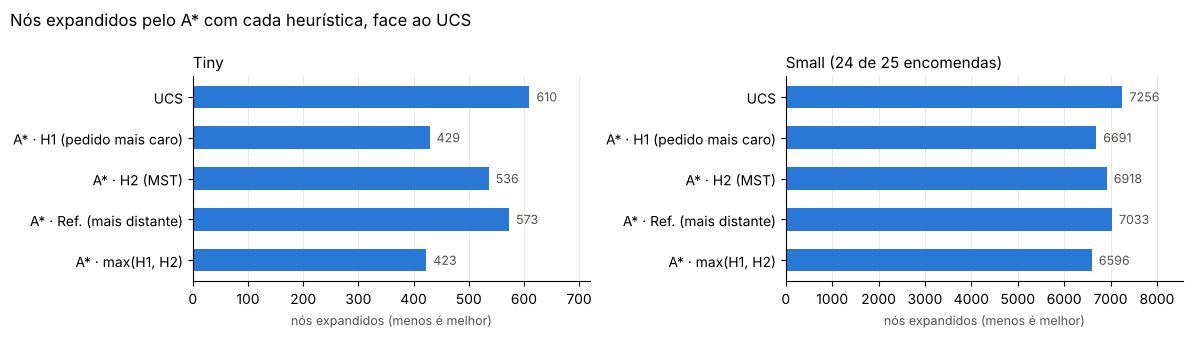

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
grafico_nos(res_tiny, "Tiny", axes[0])
grafico_nos(res_small, "Small (24 de 25 encomendas)", axes[1])
fig.suptitle("Nós expandidos pelo A* com cada heurística, face ao UCS", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

In [15]:
subs_small = subproblemas_do_plano(small, atr_small)
adm_small, resumo_adm_small = tabela_admissibilidade(subs_small, max_estados=60)
resumo_adm_small

,estados,violacoes,h_sobre_hestrela
heurística,,,
H1 (pedido mais caro),44,0,0.604
H2 (MST),44,0,0.508
Ref. (mais distante),44,0,0.446
"max(H1, H2)",44,0,0.606


In [16]:
plano_small = planos_small[("A*", "H1 (pedido mais caro)")]
print(f"Distância total: {plano_small['distancia_km']} km\n")
mostrar_rotas(small, plano_small)

Distância total: 879.45 km

Veículo 1 · dia 30/10 · 192.9 km · fim às 14:06 · verificador: viável=True, km confere=True
   06:00  [ 7] Centro de Recolha 1    início no armazém
   07:25  [ 4] Courela Carvalho       recolher em 4 (3 itens) às 07:15
   08:25  [ 6] Campos Oliveira        recolher em 6 (6 itens) às 08:15
   08:55  [ 1] Hortas Valente         recolher em 1 (2 itens) às 08:45
   09:40  [ 2] Campos Leite           recolher em 2 (5 itens) às 09:30
   10:24  [ 3] Horta Morais           recolher em 3 (1 itens) às 10:14
   11:33  [ 7] Centro de Recolha 1    armazém: descarrega 17, carrega 15
   12:07  [10] Restaurante 3          entregar em 10 (2 encomendas) às 11:57
   12:22  [ 8] Casa 1                 entregar em 8 (1 encomendas) às 12:12
   13:40  [11] Loja 4                 entregar em 11 (1 encomendas) às 13:30
   14:06  [ 7] Centro de Recolha 1    armazém: descarrega 0, carrega 0

Veículo 2 · dia 30/10 · 286.67 km · fim às 15:46 · verificador: viável=True, km confere=True
 

In [17]:
mapa_rotas(small, plano_small)

## 5. Análise crítica

### 5.1 Correção
- **Todas as rotas passam no `verificar_viabilidade` do `model.py`**, com os km a confirmar ao cêntimo.
- **O A\* dá sempre o mesmo valor que o UCS**, com qualquer heurística: 601,97 km no *tiny* e 879,45 km no *small*. Isto confirma, na prática, que as heurísticas são admissíveis.
- **No teste estado a estado (secções 3.3 e 4.2), nenhuma heurística sobrestimou** h\*.

### 5.2 Nós expandidos e qualidade das heurísticas
| | UCS | A\* H1 | A\* H2 | A\* Ref. | A\* max(H1, H2) |
|---|---|---|---|---|---|
| *Tiny* | 610 | **429 (−30 %)** | 536 (−12 %) | 573 (−6 %) | 423 (−31 %) |
| *Small* | 7256 | **6691 (−8 %)** | 6918 (−5 %) | 7033 (−3 %) | 6596 (−9 %) |

- **H1 (pedido mais caro) é a heurística mais útil nos dois conjuntos.** É também a que fica mais perto de h\*: h/h\* ≈ 0,73 no *tiny* e 0,60 no *small*, contra ≈ 0,61 e 0,51 da H2. Isto confirma o que esperávamos: conhecer a regra produtor → armazém → cliente vale mais do que ligar todas as paragens.
- **H2 (MST) ajuda, mas menos.** Liga todas as paragens pendentes, mas não sabe que é obrigatório voltar ao armazém entre a recolha e a entrega.
- **max(H1, H2) é a melhor em nós**, mas por pouco. A H1 já domina quase sempre.
- **Porque é que a poupança é modesta, sobretudo no *small*:**
  - As podas por becos sem saída e por dominância já cortam a maior parte do espaço, por isso até o UCS é barato.
  - As heurísticas só contam km e ignoram as esperas pelas janelas e as viagens extra impostas pela capacidade. Ficam a 60–73 % do custo real.

### 5.3 Tempos de execução
- No *tiny*, todas as configurações correm em menos de 0,1 s. No *small*, demoram cerca de 1 a 2 s. Os tempos variam ligeiramente entre execuções, por isso usamos a mediana de 3.
- **No *small*, o A\* com heurística não é mais rápido do que o UCS**, apesar de expandir menos nós. O cálculo da heurística em cada nó (sobretudo a MST) anula o ganho a esta escala.
- **Do *tiny* para o *small*, o UCS expande cerca de 12 vezes mais nós.** Com mais encomendas por veículo e por dia, o crescimento seria muito mais rápido. Aí, a força da heurística passa a ser decisiva.

### 5.4 Greedy contra A\*
| | Greedy H1 | Greedy H2 | Greedy Ref. |
|---|---|---|---|
| *Tiny* (km acima do ótimo) | +7,62 (1,3 %) | +7,62 | +7,62 |
| *Small* (km acima do ótimo) | **+1,08 (0,1 %)** | +60,97 (6,9 %) | +34,13 (3,9 %) |

- **O Greedy expande muito menos nós e é o mais rápido, mas não garante o ótimo.**
- **Com H1, o Greedy fica quase no ótimo.**
- **Com H2, o Greedy é o mais rápido, mas no *small* faz quase mais 61 km.** Uma heurística que minimiza "ligar pontos" sem conhecer a ordem obrigatória guia mal uma pesquisa que só olha para h.

### 5.5 Limitações
1. **A divisão das encomendas pelos veículos é fixada antes da pesquisa**, por inserção mais barata. A pesquisa é ótima dentro de cada veículo e dia, mas o plano global depende dessa divisão. No *tiny*, a ordem de inserção muda o total entre cerca de 610 e 771 km.
   - Minimizar km faz com que um veículo faça quase tudo no *tiny*. Os dois partem do mesmo armazém e visitam os mesmos produtores, por isso dividir o trabalho duplica viagens.
2. **O *small* não tem solução completa com a regra "uma encomenda do dia, um veículo".** Está provado na secção 4.1. A encomenda 9 fica de fora.
3. **A poda por dominância supõe que chegar mais cedo nunca é pior.** Há uma exceção teórica: chegar mais tarde ao armazém atrasa o início da contagem das 24 h. Neste conjunto de dados não teve impacto (todas as rotas foram validadas), mas é uma aproximação.
4. **As ações são agregadas.** Recolher tudo o que a janela permite e carregar todas as encomendas prontas reduz muito o espaço de procura, mas pode excluir soluções muito específicas.

### 5.6 Melhorias futuras
1. **Partilhar recolhas entre veículos no mesmo dia**, sincronizando as chegadas ao armazém. Resolveria o *small* por completo.
2. **Otimizar a divisão das encomendas pelos veículos**, com o CSP ou com uma pesquisa local que troque encomendas entre veículos (ligação ao Hill-Climbing do grupo).
3. **Heurísticas que contem o tempo:** esperas inevitáveis pelas janelas e viagens extra quando a carga ultrapassa a capacidade.
4. **Hill-Climbing sobre a solução do Greedy**, que é a fase seguinte do grupo, a partir das rotas deste notebook.

## 6. Conclusão
- **A pesquisa informada resolve o *tiny* de forma ótima:** 601,97 km com os 2 veículos, com todas as rotas confirmadas pelo verificador do `model.py`.
- **As duas heurísticas do grupo são admissíveis**, na teoria e no teste empírico. **H1 (pedido mais caro) é a mais informada e a que mais reduz os nós expandidos**, e com ela o Greedy fica quase no ótimo. **H2 (MST) é admissível mas mais fraca**, porque ignora a passagem obrigatória pelo armazém.
- **No *small*, a modelação mostrou um limite real do problema:** sem partilhar recolhas entre veículos, uma das 25 encomendas não pode ser servida. Isto aponta diretamente para as melhorias futuras.
- **Ferramentas:** Python, pandas para os dados, `heapq` para a fronteira, o `model.py` do grupo para a validação, matplotlib e folium para os resultados.